# Détection satellitaire de zones forestières à risque d'incendie — ViT vs Swin Transformer

Ce notebook implémente le fine-tuning et la comparaison de deux architectures **Vision Transformers** (`google/vit-base-patch16-224` et `microsoft/swin-tiny-patch4-window7-224`) sur le *Wildfire Prediction Dataset* (imagerie satellitaire RGB, classification binaire `wildfire` / `nowildfire`).

**Pipeline :**
1. Configuration de l'environnement et reproductibilité
2. Téléchargement et exploration des données (EDA)
3. Prétraitement, data augmentation et boucle d'entraînement
4. Fine-tuning de ViT-Base et Swin-Tiny
5. Évaluation comparative (métriques, courbes, matrices de confusion)
6. Explicabilité (*Attention Rollout*) et analyse d'erreurs

## 1. Configuration de l'environnement et reproductibilité
Installation des bibliothèques nécessaires, fixation des graines aléatoires (`SEED = 42`), détection du GPU et activation de la précision mixte (`bfloat16` / `float16`). `LOAD_TRUNCATED_IMAGES` est activé pour gérer quelques fichiers JPEG tronqués présents dans le jeu de données.

In [1]:
!pip install -q transformers accelerate timm kagglehub scikit-learn seaborn

import os, time, random, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    get_cosine_schedule_with_warmup,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
from tqdm.auto import tqdm

# Évite les crashs sur quelques JPEG tronqués connus dans ce dataset
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

print(f"Device : {DEVICE} | GPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"Précision mixte : {AMP_DTYPE}")

Device : cuda | GPU : NVIDIA L4
Précision mixte : torch.bfloat16


## 2. Chargement et exploration des données (EDA)
Téléchargement du *Wildfire Prediction Dataset* via `kagglehub`, vérification de la répartition des classes sur les ensembles `train`, `valid` et `test`, puis visualisation d'un échantillon représentatif des deux classes.

In [2]:
import kagglehub

raw_path = Path(kagglehub.dataset_download("abdelghaniaaba/wildfire-prediction-dataset"))
print("Téléchargé dans :", raw_path)

# Localise automatiquement le dossier racine contenant train/valid/test
DATA_DIR = next(p for p in [raw_path, *raw_path.rglob("*")] if (p / "train").is_dir() and (p / "test").is_dir())
print("DATA_DIR :", DATA_DIR)

for split in ["train", "valid", "test"]:
    split_dir = DATA_DIR / split
    counts = {cls.name: len(list(cls.glob("*"))) for cls in sorted(split_dir.iterdir()) if cls.is_dir()}
    print(f"{split:5s} -> {counts} (total: {sum(counts.values())})")

100%|██████████| 1.45G/1.45G [01:18<00:00, 19.8MB/s]

Extracting files...


Téléchargé dans : /root/.cache/kagglehub/datasets/abdelghaniaaba/wildfire-prediction-dataset/versions/1
DATA_DIR : /root/.cache/kagglehub/datasets/abdelghaniaaba/wildfire-prediction-dataset/versions/1
train -> {'nowildfire': 14500, 'wildfire': 15750} (total: 30250)
valid -> {'nowildfire': 2820, 'wildfire': 3480} (total: 6300)
test  -> {'nowildfire': 2820, 'wildfire': 3480} (total: 6300)


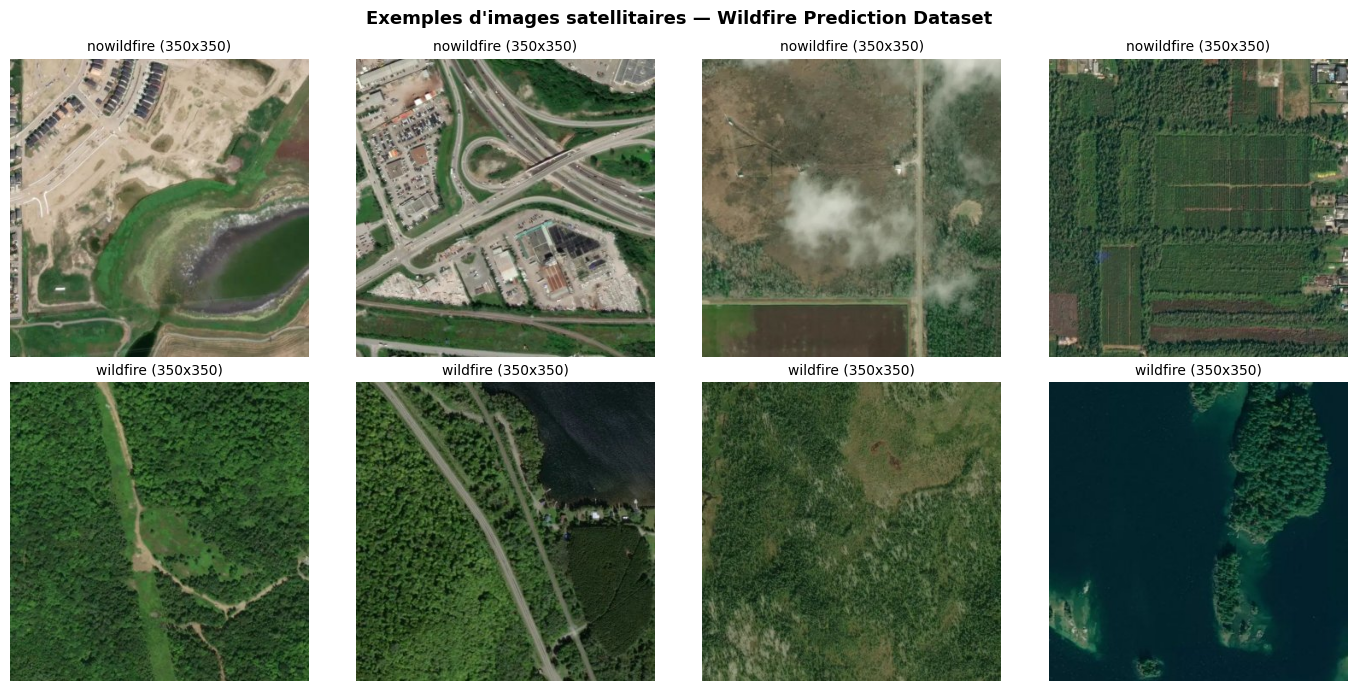

In [3]:
# Chargeur robuste au cas où un fichier serait complètement illisible
def safe_pil_loader(path):
    try:
        with open(path, "rb") as f:
            img = Image.open(f)
            return img.convert("RGB")
    except Exception:
        return Image.new("RGB", (224, 224), color=(0, 0, 0))

# Figure 1 : 4 exemples nowildfire + 4 exemples wildfire
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls_name in enumerate(["nowildfire", "wildfire"]):
    img_paths = random.sample(list((DATA_DIR / "train" / cls_name).glob("*.jpg")), 4)
    for col, img_path in enumerate(img_paths):
        img = safe_pil_loader(img_path)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{cls_name} ({img.size[0]}x{img.size[1]})", fontsize=10)
        axes[row, col].axis("off")

plt.suptitle("Exemples d'images satellitaires — Wildfire Prediction Dataset", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "dataset_samples.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Pipeline de prétraitement, d'entraînement et d'évaluation
Les images sont redimensionnées en `224×224` et normalisées selon les statistiques de chaque modèle pré-entraîné. Une *data augmentation* adaptée à la télédétection (retournements horizontal/vertical et rotations aléatoires) est appliquée uniquement sur l'ensemble d'entraînement. L'optimisation utilise `AdamW` avec un *cosine schedule* (10 % de *warmup*) et conserve le meilleur checkpoint selon le F1-Score en validation.

In [4]:
BATCH_SIZE = 64
EPOCHS = 3
LR = 3e-5
NUM_WORKERS = min(4, os.cpu_count() or 2)


def build_dataloaders(model_name):
    processor = AutoImageProcessor.from_pretrained(model_name)
    mean = processor.image_mean
    std = processor.image_std

    train_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    eval_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_ds = datasets.ImageFolder(DATA_DIR / "train", transform=train_tf, loader=safe_pil_loader)
    valid_ds = datasets.ImageFolder(DATA_DIR / "valid", transform=eval_tf, loader=safe_pil_loader)
    test_ds  = datasets.ImageFolder(DATA_DIR / "test",  transform=eval_tf, loader=safe_pil_loader)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
    valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    return train_loader, valid_loader, test_loader, train_ds.classes, (mean, std)


@torch.no_grad()
def evaluate_model(model, loader, measure_latency=False):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    all_preds, all_probs, all_labels = [], [], []

    if measure_latency and torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)

        probs = torch.softmax(logits.float(), dim=-1)[:, 1]
        preds = logits.argmax(dim=-1)

        total_loss += loss.item() * images.size(0)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    if measure_latency and torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    n = len(all_labels)
    metrics = {
        "loss": total_loss / n,
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, pos_label=1),
        "recall": recall_score(all_labels, all_preds, pos_label=1),
        "f1": f1_score(all_labels, all_preds, pos_label=1),
        "roc_auc": roc_auc_score(all_labels, all_probs),
        "ms_per_image": (elapsed / n) * 1000.0,
        "y_true": np.array(all_labels),
        "y_pred": np.array(all_preds),
        "y_prob": np.array(all_probs),
    }
    return metrics


def train_and_evaluate(model_name, short_name):
    print(f"\n{'='*60}\nEntraînement : {short_name} ({model_name})\n{'='*60}")
    train_loader, valid_loader, test_loader, classes, norm_stats = build_dataloaders(model_name)
    print("Classes :", {i: c for i, c in enumerate(classes)})

    model = AutoModelForImageClassification.from_pretrained(
        model_name,
        num_labels=len(classes),
        id2label={i: c for i, c in enumerate(classes)},
        label2id={c: i for i, c in enumerate(classes)},
        ignore_mismatched_sizes=True,
    ).to(DEVICE)

    n_params_m = sum(p.numel() for p in model.parameters()) / 1e6
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
    )
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))

    history = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}
    best_f1 = -1.0
    ckpt_path = f"best_{short_name}.pt"

    train_start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        pbar = tqdm(train_loader, desc=f"{short_name} | Époque {epoch}/{EPOCHS}")
        for images, labels in pbar:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                logits = model(pixel_values=images).logits
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item() * images.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")

        train_loss = running_loss / len(train_loader.dataset)
        val_metrics = evaluate_model(model, valid_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_f1"].append(val_metrics["f1"])
        history["val_acc"].append(val_metrics["accuracy"])

        print(
            f"Époque {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            torch.save(model.state_dict(), ckpt_path)

    train_time_s = time.perf_counter() - train_start

    # Recharge le meilleur checkpoint pour l'évaluation finale sur test
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    test_metrics = evaluate_model(model, test_loader, measure_latency=True)
    test_metrics["train_time_s"] = train_time_s
    test_metrics["params_m"] = n_params_m

    print(
        f"\n[TEST {short_name}] Acc: {test_metrics['accuracy']:.4f} | "
        f"Prec: {test_metrics['precision']:.4f} | Rec: {test_metrics['recall']:.4f} | "
        f"F1: {test_metrics['f1']:.4f} | AUC: {test_metrics['roc_auc']:.4f} | "
        f"Latence: {test_metrics['ms_per_image']:.2f} ms/img | Temps train: {train_time_s:.1f}s"
    )

    return {
        "model_name": model_name,
        "short_name": short_name,
        "ckpt_path": ckpt_path,
        "history": history,
        "test": test_metrics,
        "classes": classes,
        "norm_stats": norm_stats,
    }

## 4. Entraînement comparatif : ViT-Base vs Swin-Tiny
Fine-tuning sur 3 époques de deux paradigmes Transformers :
- **ViT-Base** : attention globale sur des patchs `16×16`.
- **Swin-Tiny** : architecture hiérarchique à fenêtres locales décalées (*Shifted Windows*).

In [5]:
vit_res = train_and_evaluate("google/vit-base-patch16-224", "ViT-Base")
torch.cuda.empty_cache()


Entraînement : ViT-Base (google/vit-base-patch16-224)


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

Classes : {0: 'nowildfire', 1: 'wildfire'}


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

... (5 outputs left out)

ViT-Base | Époque 2/3:   0%|          | 0/473 [00:00<?, ?it/s]

Époque 2/3 | Train Loss: 0.0289 | Val Loss: 0.0235 | Val Acc: 0.9925 | Val F1: 0.9932


ViT-Base | Époque 3/3:   0%|          | 0/473 [00:00<?, ?it/s]

Époque 3/3 | Train Loss: 0.0129 | Val Loss: 0.0209 | Val Acc: 0.9943 | Val F1: 0.9948

[TEST ViT-Base] Acc: 0.9930 | Prec: 0.9971 | Rec: 0.9902 | F1: 0.9937 | AUC: 0.9998 | Latence: 1.49 ms/img | Temps train: 447.0s


In [6]:
swin_res = train_and_evaluate("microsoft/swin-tiny-patch4-window7-224", "Swin-Tiny")
torch.cuda.empty_cache()


Entraînement : Swin-Tiny (microsoft/swin-tiny-patch4-window7-224)


preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

Classes : {0: 'nowildfire', 1: 'wildfire'}


config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

... (5 outputs left out)

Swin-Tiny | Époque 2/3:   0%|          | 0/473 [00:00<?, ?it/s]

Époque 2/3 | Train Loss: 0.0286 | Val Loss: 0.0231 | Val Acc: 0.9941 | Val F1: 0.9947


Swin-Tiny | Époque 3/3:   0%|          | 0/473 [00:00<?, ?it/s]

Époque 3/3 | Train Loss: 0.0141 | Val Loss: 0.0203 | Val Acc: 0.9941 | Val F1: 0.9947

[TEST Swin-Tiny] Acc: 0.9957 | Prec: 0.9960 | Rec: 0.9963 | F1: 0.9961 | AUC: 0.9998 | Latence: 1.16 ms/img | Temps train: 322.4s


## 5. Résultats quantitatifs et matrices de confusion
Synthèse des performances sur le jeu de test (Accuracy, Précision, Rappel, F1-Score, ROC-AUC et latence d'inférence), accompagnée des courbes d'apprentissage et des matrices de confusion.


=== TABLEAU COMPARATIF (COPIABLE POUR LE README & LE RAPPORT) ===
| Modèle    |   Paramètres (M) |   Accuracy |   Précision |   Rappel |   F1-Score |   ROC-AUC |   Latence (ms/img) |   Temps Train (s) |
|:----------|-----------------:|-----------:|------------:|---------:|-----------:|----------:|-------------------:|------------------:|
| ViT-Base  |             85.8 |      99.3  |       99.71 |    99.02 |      99.37 |     99.98 |               1.49 |             447   |
| Swin-Tiny |             27.5 |      99.57 |       99.6  |    99.63 |      99.61 |     99.98 |               1.16 |             322.4 |


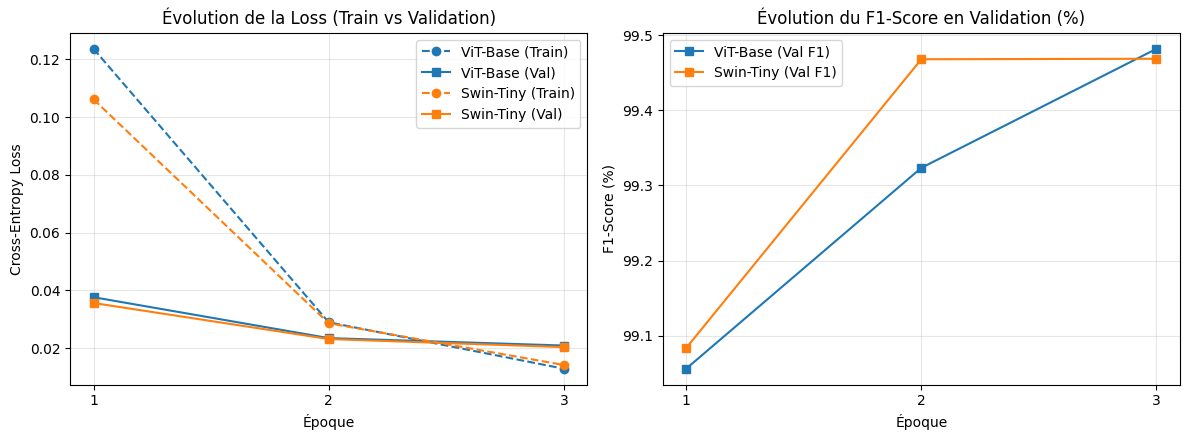

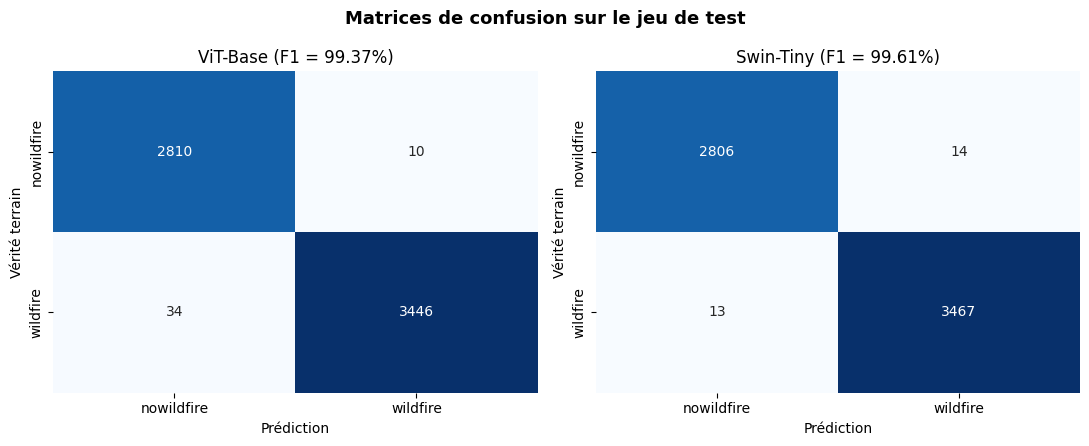

In [7]:
# 1. Tableau récapitulatif exporté en CSV et affiché en Markdown
rows = []
for r in [vit_res, swin_res]:
    m = r["test"]
    rows.append({
        "Modèle": r["short_name"],
        "Paramètres (M)": round(m["params_m"], 1),
        "Accuracy": round(m["accuracy"] * 100, 2),
        "Précision": round(m["precision"] * 100, 2),
        "Rappel": round(m["recall"] * 100, 2),
        "F1-Score": round(m["f1"] * 100, 2),
        "ROC-AUC": round(m["roc_auc"] * 100, 2),
        "Latence (ms/img)": round(m["ms_per_image"], 2),
        "Temps Train (s)": round(m["train_time_s"], 1),
    })

summary_df = pd.DataFrame(rows)
summary_df.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)
print("\n=== TABLEAU COMPARATIF (COPIABLE POUR LE README & LE RAPPORT) ===")
print(summary_df.to_markdown(index=False))

# 2. Figure 2 : Courbes d'entraînement (Loss & F1 Validation)
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for r, color in [(vit_res, "#1f77b4"), (swin_res, "#ff7f0e")]:
    axes[0].plot(epochs_range, r["history"]["train_loss"], "--o", color=color, label=f"{r['short_name']} (Train)")
    axes[0].plot(epochs_range, r["history"]["val_loss"], "-s", color=color, label=f"{r['short_name']} (Val)")
    axes[1].plot(epochs_range, [x * 100 for x in r["history"]["val_f1"]], "-s", color=color, label=f"{r['short_name']} (Val F1)")

axes[0].set_title("Évolution de la Loss (Train vs Validation)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(list(epochs_range))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Évolution du F1-Score en Validation (%)")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("F1-Score (%)")
axes[1].set_xticks(list(epochs_range))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. Figure 3 : Matrices de confusion côte à côte
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, r in zip(axes, [vit_res, swin_res]):
    cm = confusion_matrix(r["test"]["y_true"], r["test"]["y_pred"])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=r["classes"],
        yticklabels=r["classes"],
        ax=ax,
        cbar=False,
    )
    ax.set_title(f"{r['short_name']} (F1 = {r['test']['f1']*100:.2f}%)")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Vérité terrain")

plt.suptitle("Matrices de confusion sur le jeu de test", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Explicabilité (*Attention Rollout*) et analyse d'erreurs
Extraction des cartes d'attention agrégées de ViT-Base afin de visualiser les zones forestières qui guident la classification, suivie d'une inspection des faux positifs et faux négatifs.

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


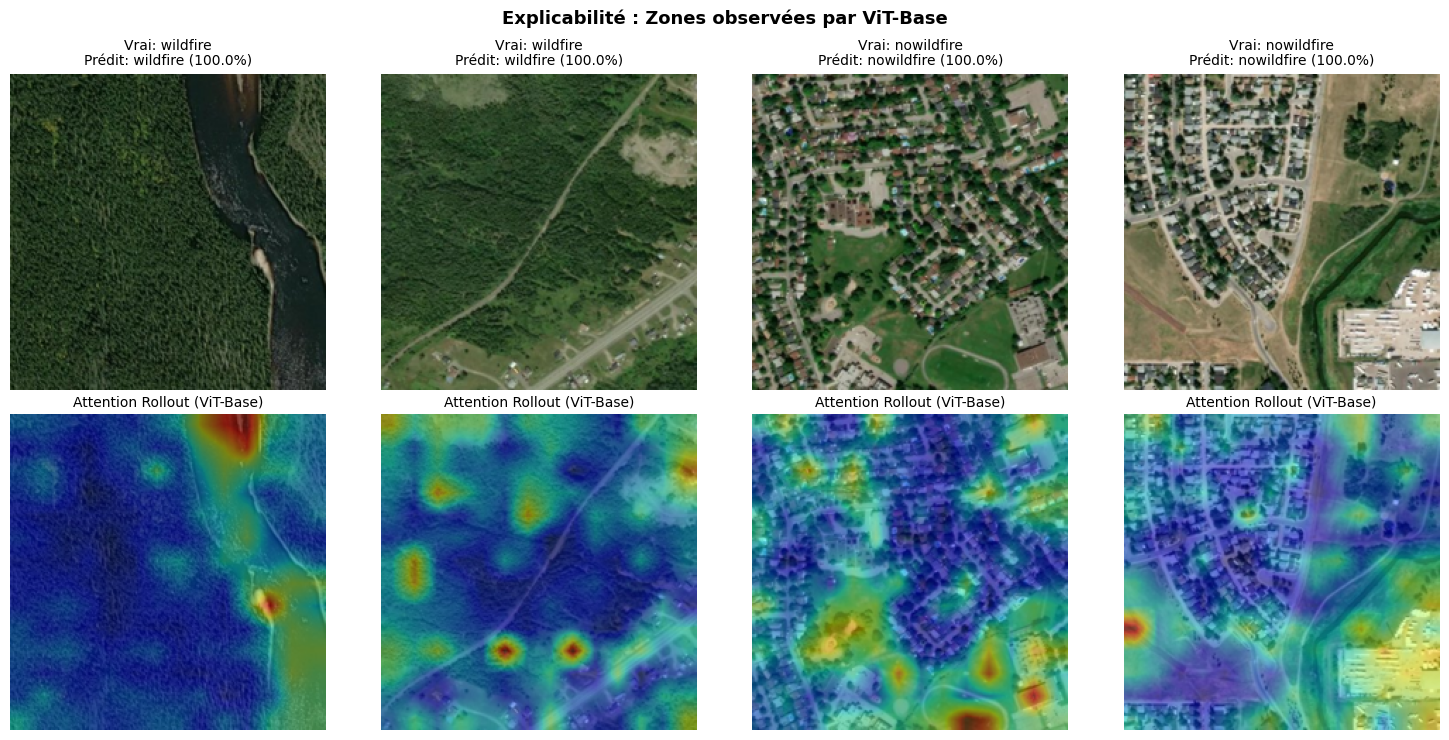

ViT-Base sur test -> Faux Positifs : 10 | Faux Négatifs : 34


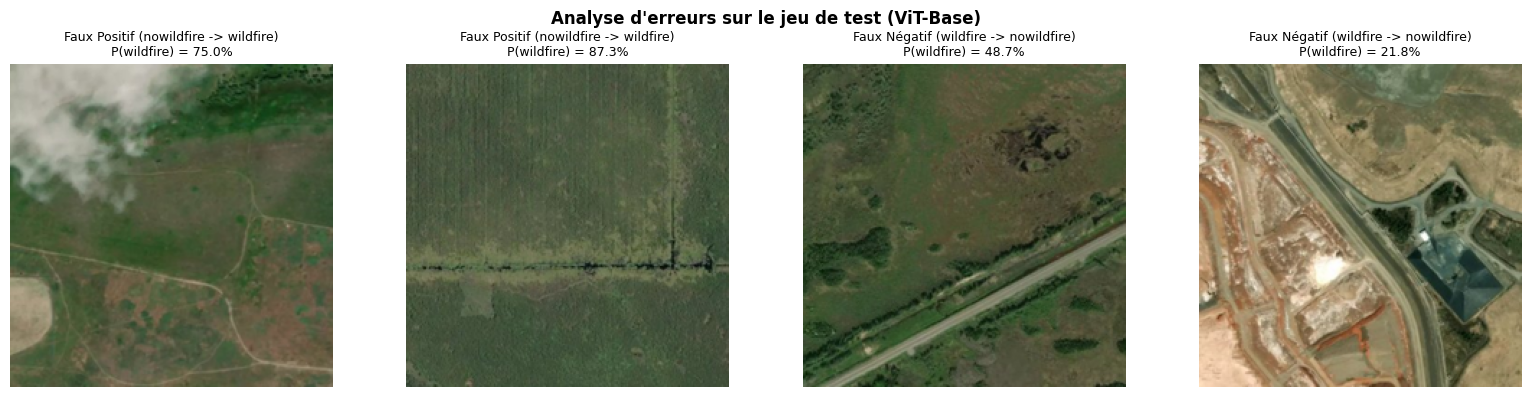

In [8]:
# Recharge ViT-Base avec attn_implementation="eager" pour exposer les poids d'attention
vit_attn_model = AutoModelForImageClassification.from_pretrained(
    vit_res["model_name"],
    num_labels=2,
    ignore_mismatched_sizes=True,
    attn_implementation="eager",
).to(DEVICE)
vit_attn_model.load_state_dict(torch.load(vit_res["ckpt_path"], map_location=DEVICE))
vit_attn_model.eval()

mean, std = vit_res["norm_stats"]
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])
test_ds = datasets.ImageFolder(DATA_DIR / "test", transform=eval_tf, loader=safe_pil_loader)


@torch.no_grad()
def compute_attention_rollout(model, img_tensor):
    outputs = model(pixel_values=img_tensor.unsqueeze(0).to(DEVICE), output_attentions=True)
    probs = torch.softmax(outputs.logits, dim=-1)[0].cpu().numpy()
    num_tokens = outputs.attentions[0].shape[-1]
    eye = torch.eye(num_tokens, device=DEVICE)

    rollout = eye.clone()
    for attn in outputs.attentions:
        attn_fused = attn[0].mean(dim=0)  # moyenne sur les 12 têtes d'attention
        a = 0.5 * attn_fused + 0.5 * eye
        a = a / a.sum(dim=-1, keepdim=True)
        rollout = a @ rollout

    mask = rollout[0, 1:].reshape(14, 14).unsqueeze(0).unsqueeze(0)
    mask = F.interpolate(mask, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    return mask, probs


# Figure 4 : 4 cartes d'attention (2 wildfire + 2 nowildfire bien classées)
y_true = vit_res["test"]["y_true"]
y_pred = vit_res["test"]["y_pred"]
correct_wf = np.where((y_true == 1) & (y_pred == 1))[0]
correct_no = np.where((y_true == 0) & (y_pred == 0))[0]
selected_idx = list(np.random.choice(correct_wf, 2, replace=False)) + list(np.random.choice(correct_no, 2, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for col, idx in enumerate(selected_idx):
    img_path, label = test_ds.samples[idx]
    orig_img = safe_pil_loader(img_path).resize((224, 224))
    img_tensor, _ = test_ds[idx]
    heatmap, probs = compute_attention_rollout(vit_attn_model, img_tensor)
    pred_lbl = vit_res["classes"][int(np.argmax(probs))]
    conf = np.max(probs) * 100

    axes[0, col].imshow(orig_img)
    axes[0, col].set_title(f"Vrai: {vit_res['classes'][label]}\nPrédit: {pred_lbl} ({conf:.1f}%)", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].imshow(orig_img)
    axes[1, col].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[1, col].set_title("Attention Rollout (ViT-Base)", fontsize=10)
    axes[1, col].axis("off")

plt.suptitle("Explicabilité : Zones observées par ViT-Base", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "vit_attention_maps.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 5 : Analyse d'erreurs (2 Faux Positifs + 2 Faux Négatifs de ViT-Base)
fp_idx = np.where((y_true == 0) & (y_pred == 1))[0]
fn_idx = np.where((y_true == 1) & (y_pred == 0))[0]
print(f"ViT-Base sur test -> Faux Positifs : {len(fp_idx)} | Faux Négatifs : {len(fn_idx)}")

err_samples = (
    [(i, "Faux Positif (nowildfire -> wildfire)") for i in fp_idx[:2]]
    + [(i, "Faux Négatif (wildfire -> nowildfire)") for i in fn_idx[:2]]
)

if err_samples:
    fig, axes = plt.subplots(1, len(err_samples), figsize=(4 * len(err_samples), 4))
    if len(err_samples) == 1:
        axes = [axes]
    for ax, (idx, err_title) in zip(axes, err_samples):
        img_path, _ = test_ds.samples[idx]
        orig_img = safe_pil_loader(img_path).resize((224, 224))
        prob_wf = vit_res["test"]["y_prob"][idx] * 100
        ax.imshow(orig_img)
        ax.set_title(f"{err_title}\nP(wildfire) = {prob_wf:.1f}%", fontsize=9)
        ax.axis("off")

    plt.suptitle("Analyse d'erreurs sur le jeu de test (ViT-Base)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "error_analysis.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. Export des figures et métriques
Archivage de l'ensemble des graphiques et du tableau CSV dans `results.zip` pour intégration au dépôt GitHub et au rapport.

In [9]:
from google.colab import files

shutil.make_archive("results", "zip", RESULTS_DIR)
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>